# RD_r_and_d

> 对应代码：`EconometricsCode/code_in_notes/Chap.20/RD_r_and_d.do`（本 notebook 中的 Stata 代码与 do 文件一致）
>
> 运行方式：通过 *PyStata* 在 Jupyter 中调用 Stata，安装与使用说明见 `notebooks/PyStata.md`。

**说明**：本 notebook 的 Stata 代码与 `.do` 文件完全一致（这两个 do 文件中没有 `graph export` 命令），散点与拟合曲线、`rdplot` 图以及密度图都由 PyStata 在 notebook 中直接内联显示。

首先启动 Stata 环境，并把工作目录切换到 `code_in_notes/Chap.20`，这样 Stata 中的相对路径（如 `../datasets/...`）与同名 do 文件完全一致，图片也会输出到该目录。

In [1]:
# 配置 PyStata：启动 Stata 并注册 %%stata 魔法命令
import os
os.chdir("../../code_in_notes/Chap.20")

import stata_setup
stata_setup.config("/opt/Stata", "mp")


  ___  ____  ____  ____  ____ ®
 /__    /   ____/   /   ____/      Stata 18.0
___/   /   /___/   /   /___/       MP—Parallel Edition

 Statistics and Data Science       Copyright 1985-2023 StataCorp LLC
                                   StataCorp
                                   4905 Lakeway Drive
                                   College Station, Texas 77845 USA
                                   800-782-8272        https://www.stata.com
                                   979-696-4600        service@stata.com

Stata license: Single-user 16-core  perpetual
Serial number: 501806307019
  Licensed to: Keep calm and DO your research
               Jichun Si

Notes:
      1. Unicode is supported; see help unicode_advice.
      2. More than 2 billion observations are allowed; see help obs_advice.
      3. Maximum number of variables is set to 5,000 but can be increased;
          see help set_maxvar.


我们读入 Bronzini and Iachini (2014) 使用的意大利研发补贴数据。该项目中企业提交研发项目申请，主管部门按评审得分 `score` 排序，得分达到 75 分的项目可以获得补贴。于是 `score` 是断点回归中的**运行变量**（**running variable**），75 分是政策规定的**断点**（**cutoff**），我们关心的是补贴对企业投资销售比 `INVSALES` 的影响。

In [2]:
%%stata
clear
set more off
use ../datasets/bronzini_r_and_d.dta, clear

gen s=score-75
gen treat=s>=0
gen s2=s^2
gen s3=s^3


. clear

. set more off

. use ../datasets/bronzini_r_and_d.dta, clear

. 
. gen s=score-75

. gen treat=s>=0

. gen s2=s^2

. gen s3=s^3

. 


为把断点放到原点，我们定义中心化的运行变量 `s = score - 75`、处理变量 `treat = 1{s >= 0}`，以及 `s` 的二、三次项。断点回归的基本想法是：在 75 分附近，企业的可观测与不可观测特征都应当是连续的，因此结果变量在断点处的跳跃可以归因于补贴。

实践中最直接的实现是让 `s` 的多项式在断点两侧有各自的斜率。我们构造左右两侧的多项式项：`ls = s*(1-treat)` 在左侧（`s<0`）等于 `s`、在右侧等于 0；`rs = s*treat` 则相反。这样 `treat` 的系数就恰好是断点处的跳跃，而 `ls`、`rs` 及其高次项刻画了两侧各自的曲线形状。

In [3]:
%%stata
//左边
gen ls=s*(1-treat)
gen ls2=ls^2
gen ls3=ls^3
//右边
gen rs=s*treat
gen rs2=rs^2
gen rs3=rs^3


. //左边
. gen ls=s*(1-treat)

. gen ls2=ls^2

. gen ls3=ls^3

. //右边
. gen rs=s*treat

. gen rs2=rs^2

. gen rs3=rs^3

. 


先看全样本的**全局多项式**（**global polynomial**）回归。它只用少数几个参数就概括整条曲线，但会给远离断点的观测赋予很大的权重，估计结果对多项式阶数非常敏感，因此在实践中并不可取。这里依次列出一次、二次、三次的设定，用来说明这种敏感性：随着阶数提高，`treat` 的系数明显变化。

In [4]:
%%stata
//全样本，多项式，不要使用
reg INVSALES treat ls rs, cluster(score)
reg INVSALES treat ls ls2 rs rs2, cluster(score)
reg INVSALES treat ls ls2 ls3 rs rs2 rs3, cluster(score)


. //全样本，多项式，不要使用
. reg INVSALES treat ls rs, cluster(score)

Linear regression                               Number of obs     =        357
                                                F(3, 53)          =       1.68
                                                Prob > F          =     0.1819
                                                R-squared         =     0.0131
                                                Root MSE          =     .10402

                                 (Std. err. adjusted for 54 clusters in score)
------------------------------------------------------------------------------
             |               Robust
    INVSALES | Coefficient  std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
       treat |   .0400346   .0202325     1.98   0.053    -.0005467    .0806158
          ls |  -.0009221   .0005255    -1.75   0.085    -.0019761    .0001319
          rs |  -.0016497   .001

更稳妥的做法是把样本限制在断点附近的一个**窗宽**（**bandwidth**）内，只使用 `|s| < 10` 的企业做**局部多项式**（**local polynomial**）估计。窗口越小，函数形式误设带来的偏差越小，但可用样本越少、方差越大，这正是断点回归中经典的偏差-方差权衡（**bias-variance trade-off**）。

In [5]:
%%stata
// 分数为10的窗宽
reg INVSALES treat ls rs if s<10 & s>-10, cluster(score)
reg INVSALES treat ls ls2 rs rs2 if s<10 & s>-10, cluster(score)
reg INVSALES treat ls ls2 ls3 rs rs2 rs3 if s<10 & s>-10, cluster(score)


. // 分数为10的窗宽
. reg INVSALES treat ls rs if s<10 & s>-10, cluster(score)

Linear regression                               Number of obs     =        187
                                                F(3, 18)          =       1.50
                                                Prob > F          =     0.2493
                                                R-squared         =     0.0273
                                                Root MSE          =     .10235

                                 (Std. err. adjusted for 19 clusters in score)
------------------------------------------------------------------------------
             |               Robust
    INVSALES | Coefficient  std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
       treat |   .0499343     .03695     1.35   0.193    -.0276948    .1275633
          ls |  -.0008488   .0055424    -0.15   0.880    -.0124929    .0107953
          rs |  -.0

窗宽取多大带有主观性。Calonico, Cattaneo and Titiunik (2014) 提出的 `rdrobust` 用数据驱动的方法选择均方误差最优（**MSE-optimal**）的窗宽，并给出偏差校正（**bias-corrected**）与稳健（**robust**）的置信区间。命令输出中的 Conventional、Bias-corrected、Robust 三行分别对应三种推断方式，其中 Robust 行是推荐报告的结果。下面先人为指定 `h(10)`，再让程序自动选择窗宽。

In [6]:
%%stata
// rdrobust
rdrobust INVSALES s, c(0) h(10)
rdrobust INVSALES s, c(0)


. // rdrobust
. rdrobust INVSALES s, c(0) h(10)

Sharp RD estimates using local polynomial regression.

      Cutoff c = 0 | Left of c  Right of c            Number of obs =        35
> 7
-------------------+----------------------            BW type       =     Manua
> l
     Number of obs |       103         254            Kernel        = Triangula
> r
Eff. Number of obs |        58         129            VCE method    =         N
> N
    Order est. (p) |         1           1
    Order bias (q) |         2           2
       BW est. (h) |    10.000      10.000
       BW bias (b) |    10.000      10.000
         rho (h/b) |     1.000       1.000

Outcome: INVSALES. Running variable: s.
-------------------------------------------------------------------------------
> -
                   | Point         | Robust Inference
                   | Estimate      | z-stat        P>|z|    [95% Conf. Interval
> ]
-------------------+-----------------------------------------------------------
>

图形上，我们在窗口内分别对左右两侧拟合三次多项式：左侧回归只使用 `s<0` 的样本，右侧回归只使用 `s>=0` 的样本，再用 `predict` 得到各自的拟合值。最后把散点与两条拟合曲线画在同一张图上，断点处的垂直落差就是补贴的效应。


. // 画图
. reg INVSALES treat ls ls2 ls3 if s<0 & s>-10
note: treat omitted because of collinearity.

      Source |       SS           df       MS      Number of obs   =        58
-------------+----------------------------------   F(3, 54)        =      1.73
       Model |  .047723824         3  .015907941   Prob > F        =    0.1725
    Residual |  .497571699        54  .009214291   R-squared       =    0.0875
-------------+----------------------------------   Adj R-squared   =    0.0368
       Total |  .545295523        57  .009566588   Root MSE        =    .09599

------------------------------------------------------------------------------
    INVSALES | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
       treat |          0  (omitted)
          ls |    .033296    .100731     0.33   0.742    -.1686575    .2352495
         ls2 |   -.000515   .0211688    -0.02   0.981    -.0429559    

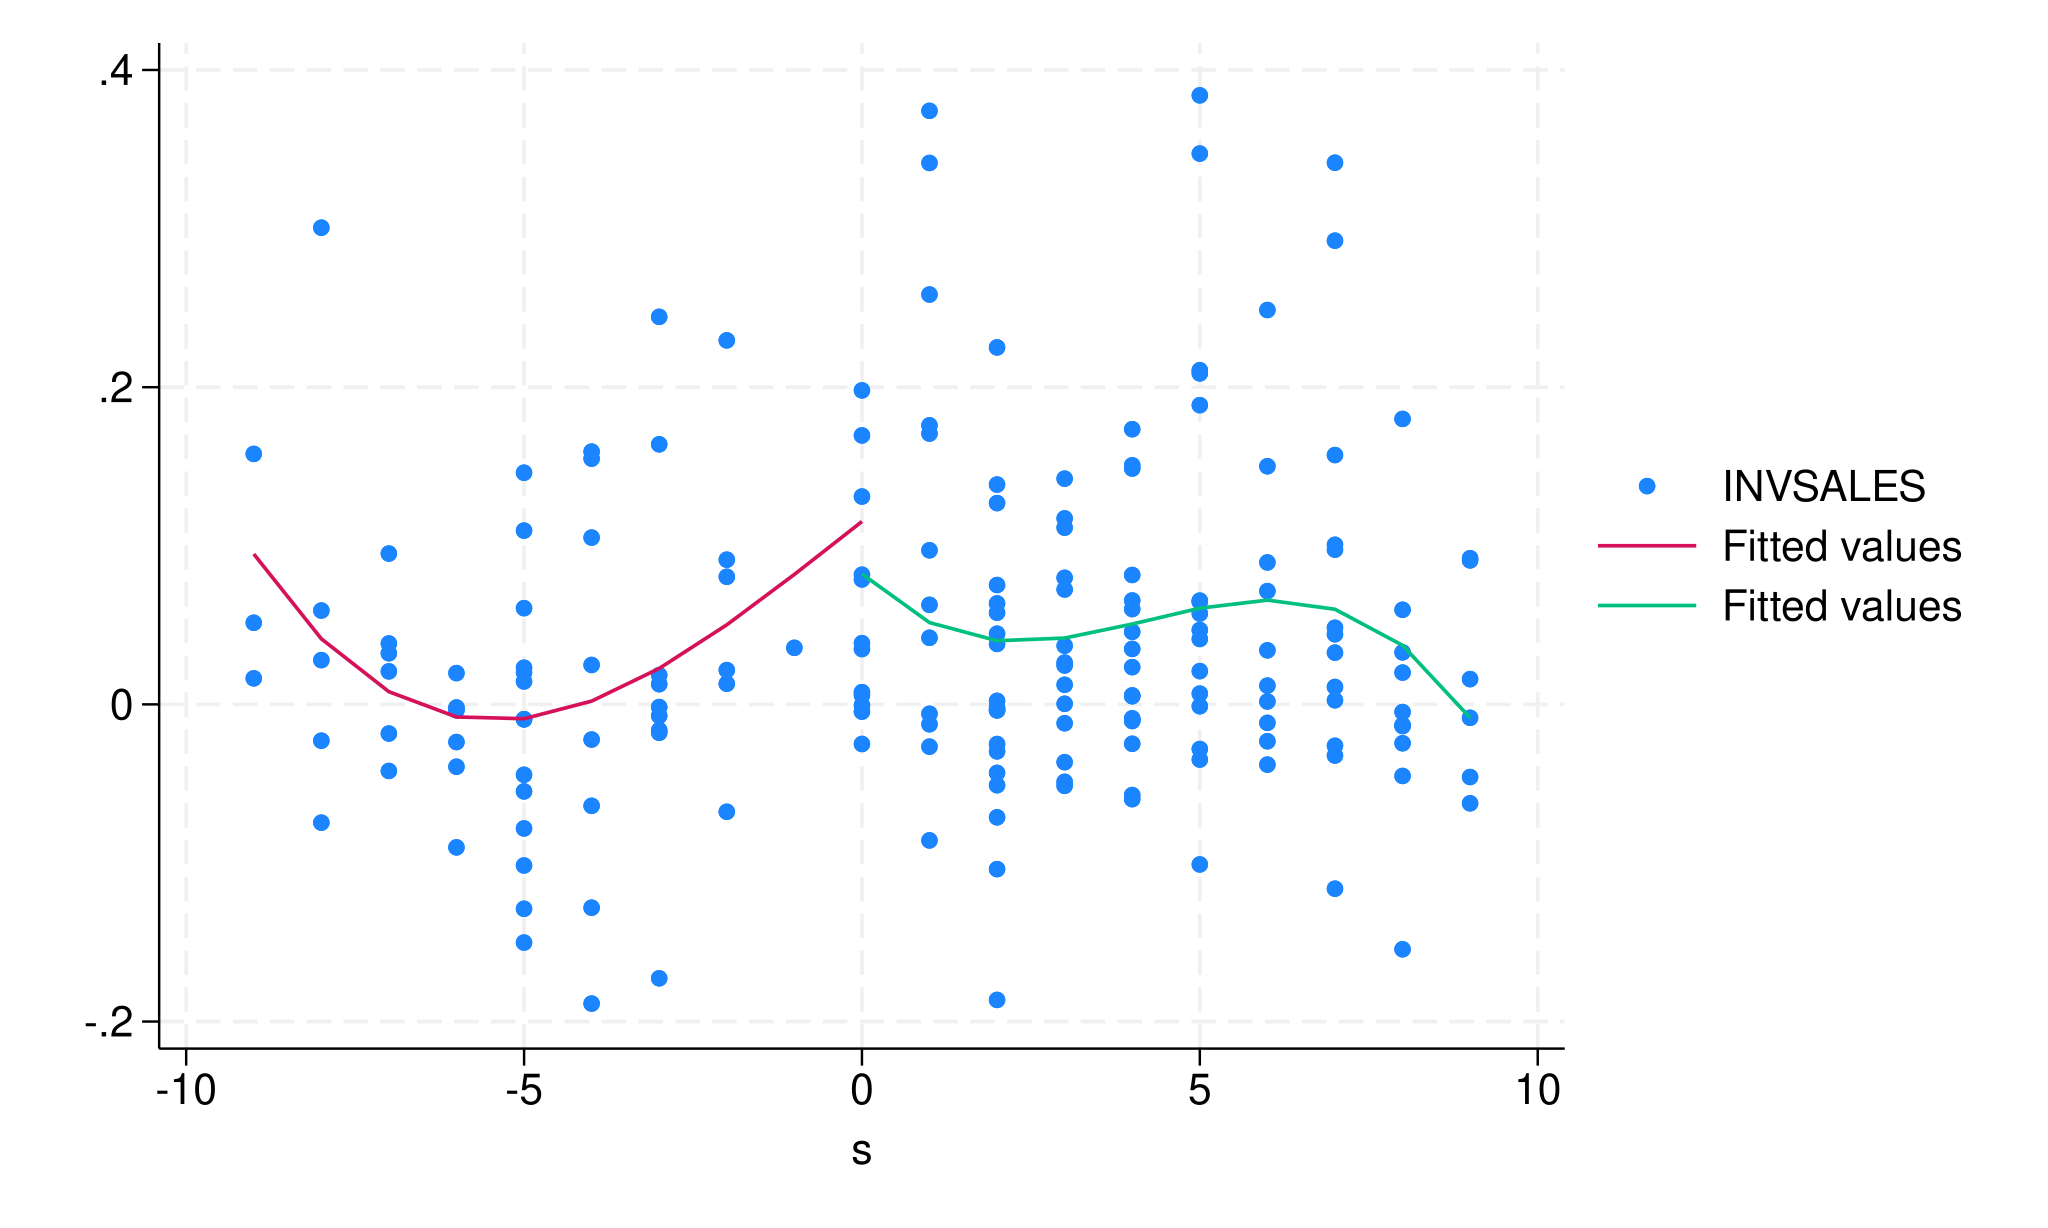

In [7]:
%%stata
// 画图
reg INVSALES treat ls ls2 ls3 if s<0 & s>-10
predict l_pred_INVSALES
reg INVSALES treat rs rs2 rs3 if s>=0 & s<10
predict r_pred_INVSALES
sort s
twoway (scatter INVSALES s if s<10 & s>-10) /// 
       (line l_pred_INVSALES s if s<=0 & s>-10) /// 
       (line r_pred_INVSALES s if s>=0 & s<10)

断点回归设计成立的前提是运行变量在断点处不能被操纵（**manipulation**），即企业无法精确地把得分做到 75 分以上。Cattaneo, Jansson and Ma (2020) 的 `rddensity` 检验断点两侧的密度是否连续：如果密度在断点处出现跳跃，说明样本在断点附近存在排序或操纵。`plot` 选项同时画出密度估计与置信带，`c(0)` 指定断点位置。


. // manipulation检验
. rddensity s, c(0) plot
Computing data-driven bandwidth selectors.

Bandwidth hr greater than the range of the data.

Point estimates and standard errors have been adjusted for repeated observation
> s.
(Use option nomasspoints to suppress this adjustment.)

RD Manipulation test using local polynomial density estimation.

     c =     0.000 | Left of c  Right of c          Number of obs =          35
> 7
-------------------+----------------------          Model         = unrestricte
> d
     Number of obs |       103         254          BW method     =         com
> b
Eff. Number of obs |        88         254          Kernel        =   triangula
> r
    Order est. (p) |         2           2          VCE method    =    jackknif
> e
    Order bias (q) |         3           3
       BW est. (h) |    31.000      31.000

Running variable: s.
------------------------------------------
            Method |      T          P>|T|
-------------------+--------------------

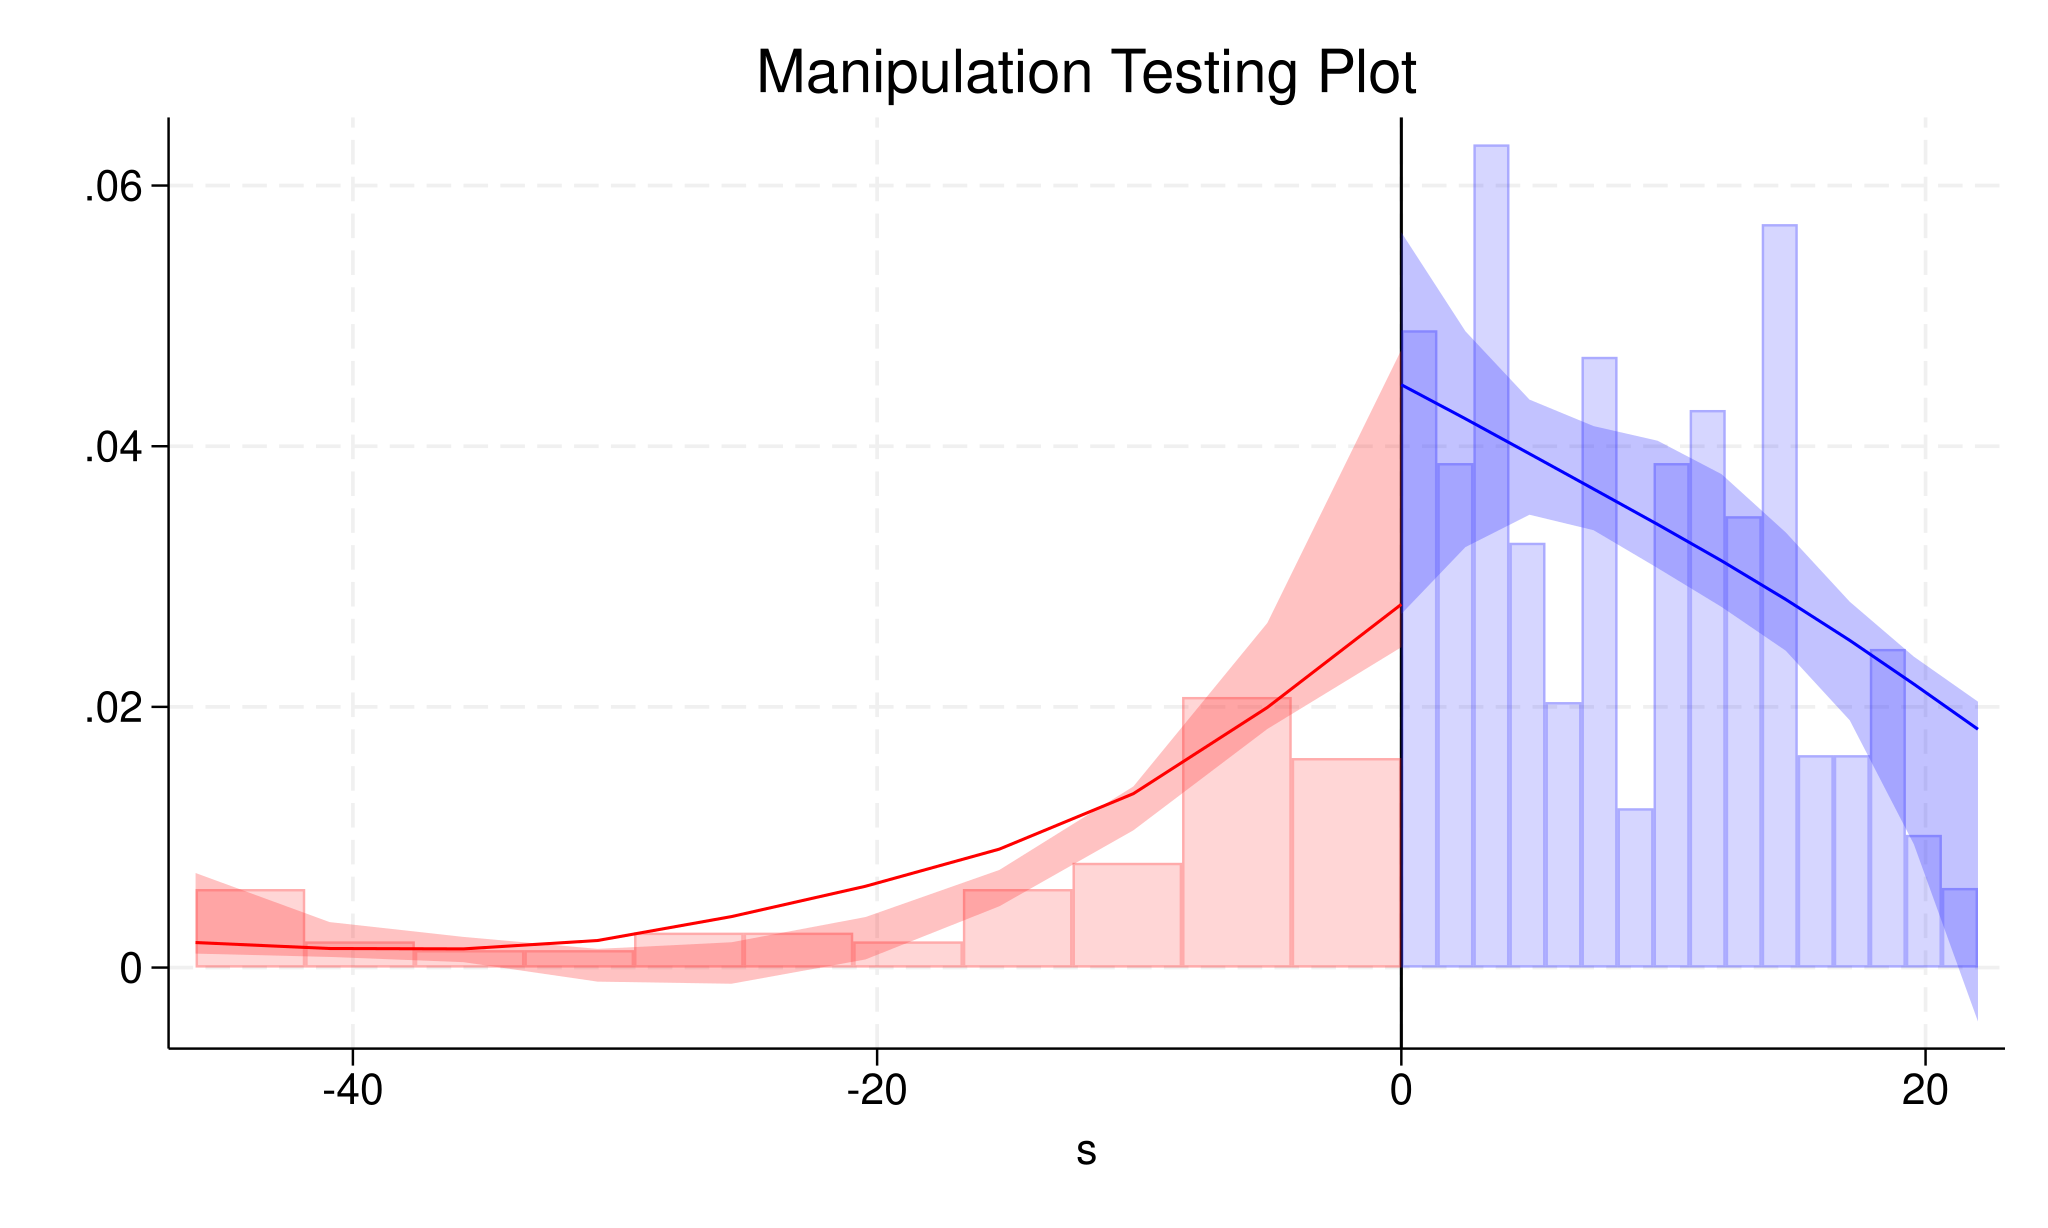

In [8]:
%%stata
// manipulation检验
rddensity s, c(0) plot